In [ ]:
# ruff: noqa: T201, T203
from __future__ import annotations

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import logging

import pandas as pd
from dotenv import load_dotenv
from tqdm import tqdm

from config.config import DATA_DIR, RUN_DIR
from config.runs_vars import SUBSET_TO_DATASET_MAP
from src.constants import PAIRS_SEPARATOR
from src.evaluate import (
    analyze_results,
    get_predictions_with_gt,
    plot_usage_histograms,
    read_run_metrics_df,
    store_run_metrics_df,
)
from src.formatting import (
    format_oracle_pairs_filepath,
    format_run_path,
    format_storing_pathes_from_run_path,
    format_subsets_ontologies_paths,
)
from src.LLM_servers.openai import OpenAIServer
from src.onto_access import OntologyAccess
from src.onto_object import OntologyEntryAttr
from src.processing import parallel_samples_process, save_oracle_pairs_with_prompts
from src.prompts.prompts import (
    prompt_direct_entity,
    prompt_direct_entity_ontological,
    prompt_direct_entity_with_synonyms,
    prompt_sequential_hierarchy,
    prompt_sequential_hierarchy_ontological,
    prompt_sequential_hierarchy_with_synonyms,
)
from src.prompts.system import BASELINE_INITIALIZATION_MESSAGE
from src.utils import load_precomputed_oracle_pairs, save_run_results

pd.set_option("display.max_rows", None)
logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [5]:
EXP_NAMES_TO_PROMPT_FUNCTIONS = {
    prompt_function.__name__.replace("prompt_", ""): prompt_function
    for prompt_function in [
        prompt_direct_entity,
        prompt_direct_entity_ontological,
        prompt_sequential_hierarchy,
        prompt_sequential_hierarchy_ontological,
        prompt_direct_entity_with_synonyms,
        prompt_sequential_hierarchy_with_synonyms,
    ]
}

In [3]:
DATASET_NAME, SET_NAME = "anatomy", "mouse-human"
# DATASET_NAME, SET_NAME = "bioml-2024", "ncit-doid"

src_onto_path, tgt_onto_path = format_subsets_ontologies_paths(DATASET_NAME, SET_NAME)

In [ ]:
onto_src = OntologyAccess(src_onto_path, annotate_on_init=True)
onto_tgt = OntologyAccess(tgt_onto_path, annotate_on_init=True)

### Pre-Validation

In [ ]:
# src_entity, tgt_entity = read_oracle_pairs(format_oracle_pairs_filepath(DATASET_NAME, SET_NAME))[0]
# try:
#     src_entity, tgt_entity = OntologyEntryAttr(src_entity, onto_src), OntologyEntryAttr(tgt_entity, onto_tgt)
# except AssertionError:
#     src_entity, tgt_entity = OntologyEntryAttr(tgt_entity, onto_src), OntologyEntryAttr(src_entity, onto_tgt)

# print(src_entity)
# print(tgt_entity)

# for name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
#     print(f"Prompt function: {name}")
#     print(prompt_function(src_entity, tgt_entity))
#     print("=" * 50)

In [4]:
for name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
    print(f"Prompt function: {name}")
    oracle_candidate_pairs = load_precomputed_oracle_pairs(DATASET_NAME, SET_NAME, prompt_function)
    print(oracle_candidate_pairs[0], sep="\n")


Prompt function: direct_entity
('http://human.owl#NCI_C32658', 'http://mouse.owl#MA_0002684', 'We have two entities from different biomedical ontologies.\nThe first one is "stomach muscularis mucosa", which belongs to the broader category "Thing"\nThe second one is "Gastric_Muscularis_Mucosa", which belongs to the broader category "Gastric_Mucosa"\n\nDo they mean the same thing? Respond with "True" or "False".')
Prompt function: direct_entity_ontological
('http://human.owl#NCI_C32658', 'http://mouse.owl#MA_0002684', 'Analyze the following entities, each originating from a distinct biomedical ontology.\nYour task is to assess whether they represent the **same ontological concept**, considering both their semantic meaning and hierarchical position.\n\n1. Source entity: "stomach muscularis mucosa"\n\t- Direct ontological parent: Thing\n\n2. Target entity: "Gastric_Muscularis_Mucosa"\n\t- Direct ontological parent: Gastric_Mucosa\n\nAre these entities **ontologically equivalent** within th

### Pre-Processing

In [14]:
ALL_DATASET_NAMES = {
    # "anatomy": ["mouse-human"],
    # "bioml-2024": ["snomed-fma.body", "snomed-ncit.neoplas", "snomed-ncit.pharm", "ncit-doid", "omim-ordo"],
    "largebio": ["fma-nci", "fma-snomed", "snomed-nci"],
}
PAIRS_WITH_PROMPTS_SUBDIR = "oracle_pairs"
prompt_functions = list(EXP_NAMES_TO_PROMPT_FUNCTIONS.values())

for dataset_name, set_names in ALL_DATASET_NAMES.items():
    for set_name in set_names:
        try:
            ontologies = []
            for onto_path in tqdm(
                format_subsets_ontologies_paths(dataset_name, set_name),
                desc=f"Loading ontologies: {dataset_name} - {set_name}",
            ):
                ontologies.append(OntologyAccess(onto_path, annotate_on_init=True))

            pairs_path = format_oracle_pairs_filepath(dataset_name, set_name)
            oracle_pairs_dir = DATA_DIR / dataset_name / set_name / PAIRS_WITH_PROMPTS_SUBDIR

            pairs_with_prompts_df = save_oracle_pairs_with_prompts(
                pairs_path, *ontologies, prompt_functions, oracle_pairs_dir, PAIRS_SEPARATOR, max_workers=2
            )
        except Exception as e:  # noqa: BLE001
            print(f"Error processing {dataset_name} - {set_name}: {e}")
            continue

Loading ontologies: largebio - fma-nci:   0%|          | 0/2 [00:00<?, ?it/s]

Loading ontologies: largebio - fma-nci:  50%|█████     | 1/2 [00:18<00:18, 18.15s/it]* Owlready2 * Creating new ontology oaei_NCI_small_overlapping_fma <data/largebio/fma-nci/oaei_NCI_small_overlapping_fma.owl#>.
* Owlready2 * ADD TRIPLE data/largebio/fma-nci/oaei_NCI_small_overlapping_fma.owl http://www.w3.org/1999/02/22-rdf-syntax-ns#type http://www.w3.org/2002/07/owl#Ontology
* Owlready2 *     ...loading ontology oaei_NCI_small_overlapping_fma from data/largebio/fma-nci/oaei_NCI_small_overlapping_fma.owl...
* Owlready2 *     ...63 properties found: Anatomic_Structure_Has_Location, Anatomic_Structure_Is_Physical_Part_Of, Biological_Process_Has_Associated_Location, Biological_Process_Has_Initiator_Chemical_Or_Drug, Biological_Process_Has_Initiator_Process, Biological_Process_Has_Result_Anatomy, Biological_Process_Has_Result_Biological_Process, Biological_Process_Has_Result_Chemical_Or_Drug, Biological_Process_Is_Part_Of_Process, Chemical_Or_Drug_Affects_Gene_Product, Chemical_Or_Drug_

* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Abbreviation: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Date_entered_modified: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.English_equivalent: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Eponym: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Language: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Latin_name__TA_: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Modified_by: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Other_Latin_equivalents: new triples are now available.
* Owlready2 * Reseting property oaei_FMA_small_overlapping_nci.Outdated_meaning: new triples are now available.
* Owlr

* Owlready2 *     ...24 properties found: Abbreviation, Date_entered_modified, English_equivalent, Eponym, Language, Latin_name__TA_, Modified_by, Other_Latin_equivalents, Outdated_meaning, Source, TA_ID, Term_status, author, authority, dimension, has_boundary, has_dimension, has_inherent_3_D_shape, has_mass, modification, name, physical_state, polarity, state_of_determination
Loading ontologies: largebio - fma-snomed:  50%|█████     | 1/2 [01:42<01:42, 102.54s/it]* Owlready2 * Creating new ontology oaei_SNOMED_small_overlapping_fma <data/largebio/fma-snomed/oaei_SNOMED_small_overlapping_fma.owl#>.
* Owlready2 * ADD TRIPLE data/largebio/fma-snomed/oaei_SNOMED_small_overlapping_fma.owl http://www.w3.org/1999/02/22-rdf-syntax-ns#type http://www.w3.org/2002/07/owl#Ontology
* Owlready2 *     ...loading ontology oaei_SNOMED_small_overlapping_fma from data/largebio/fma-snomed/oaei_SNOMED_small_overlapping_fma.owl...
* Owlready2 *     ...18 properties found: Associated_finding, Associated_mor

* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Associated_finding: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Associated_morphology: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Direct_substance: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Has_active_ingredient: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Finding_context: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Finding_informer: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Finding_site: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Interprets: new triples are now available.
* Owlready2 * Reseting property oaei_SNOMED_small_overlapping_fma.Laterality: n

* Owlready2 *     ...51 properties found: Associated_finding, Associated_morphology, Direct_substance, Has_active_ingredient, Finding_context, Finding_informer, Finding_site, Interprets, Laterality, Method, Occurrence, Procedure_site, Procedure_siteDirect, RoleGroup, Specimen_source_topography, Specimen_substance, Subject_relationship_context, Temporal_context, Access, After, Associated_with, Associated_procedure, Causative_agent, Clinical_course, Component, Direct_device, Procedure_device, Direct_morphology, Procedure_morphology, Due_to, Finding_method, Has_definitional_manifestation, Has_dose_form, Has_focus, Has_intent, Has_interpretation, Has_specimen, Priority, Procedure_context, Procedure_siteIndirect, Property, Recipient_category, Route_of_administration, Specimen_procedure, Specimen_source_morphology, Surgical_approach, Using_access_device, Using_device, Using_energy, Using_substance, has_pathological_process
Loading ontologies: largebio - snomed-nci:  50%|█████     | 1/2 [04:0

* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Anatomic_Structure_Has_Location: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Anatomic_Structure_Is_Physical_Part_Of: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Biological_Process_Has_Associated_Location: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Biological_Process_Has_Initiator_Chemical_Or_Drug: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Biological_Process_Has_Initiator_Process: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Biological_Process_Has_Result_Anatomy: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_small_overlapping_fma.Biological_Process_Has_Result_Biological_Process: new triples are now available.
* Owlready2 * Reseting property oaei_NCI_sm

* Owlready2 *     ...82 properties found: Anatomic_Structure_Has_Location, Anatomic_Structure_Is_Physical_Part_Of, Biological_Process_Has_Associated_Location, Biological_Process_Has_Initiator_Chemical_Or_Drug, Biological_Process_Has_Initiator_Process, Biological_Process_Has_Result_Anatomy, Biological_Process_Has_Result_Biological_Process, Biological_Process_Has_Result_Chemical_Or_Drug, Biological_Process_Is_Part_Of_Process, Chemical_Or_Drug_Affects_Gene_Product, Chemical_Or_Drug_Has_Mechanism_Of_Action, Chemical_Or_Drug_Has_Physiologic_Effect, Concept_In_Subset, Disease_Excludes_Abnormal_Cell, Disease_Excludes_Cytogenetic_Abnormality, Disease_Excludes_Finding, Disease_Excludes_Molecular_Abnormality, Disease_Excludes_Normal_Cell_Origin, Disease_Excludes_Normal_Tissue_Origin, Disease_Excludes_Primary_Anatomic_Site, Disease_Has_Abnormal_Cell, Disease_Has_Associated_Anatomic_Site, Disease_Has_Associated_Disease, Disease_Has_Cytogenetic_Abnormality, Disease_Has_Finding, Disease_Has_Metastat

### Run experiments


In [ ]:
MAX_WORKERS = 10
MODELS = ["gemini-2.0-flash"]  # "gpt-4o-mini"

DATASETS_MAP = {
    # "anatomy": ["mouse-human"],
    "bioml-2024": ["snomed-fma.body", "snomed-ncit.neoplas", "snomed-ncit.pharm"], # "ncit-doid", "omim-ordo"],
    "largebio": ["fma-snomed", "snomed-nci"], # "fma-nci"]
}
onto_src, onto_tgt = None, None

Processing Lines prompt_direct_entity: 100%|██████████| 2081/2081 [01:36<00:00, 21.56it/s]


Mean input tockens: 122.4
Mean output tockens: 9.0
Total input tockens: 254798
Total output tockens: 18729
Accuracy: 0.548
Precision: 0.452
Recall: 0.847
F1 Score: 0.590




Processing Lines prompt_direct_entity_ontological: 100%|██████████| 2081/2081 [01:32<00:00, 22.42it/s]


Mean input tockens: 159.5
Mean output tockens: 9.0
Total input tockens: 331955
Total output tockens: 18729
Accuracy: 0.532
Precision: 0.441
Recall: 0.826
F1 Score: 0.575




Processing Lines prompt_sequential_hierarchy: 100%|██████████| 2081/2081 [01:31<00:00, 22.82it/s]


...

Mean input tockens: 229.2
Mean output tockens: 9.0
Total input tockens: 1013857
Total output tockens: 39807
Accuracy: 0.826
Precision: 0.929
Recall: 0.874
F1 Score: 0.901




Processing Lines prompt_direct_entity_with_synonyms: 100%|██████████| 4423/4423 [03:14<00:00, 22.69it/s]


Mean input tockens: 133.2
Mean output tockens: 9.0
Total input tockens: 589233
Total output tockens: 39807
Accuracy: 0.873
Precision: 0.931
Recall: 0.928
F1 Score: 0.929




Processing Lines prompt_sequential_hierarchy_with_synonyms: 100%|██████████| 4423/4423 [03:12<00:00, 22.93it/s]


Mean input tockens: 171.6
Mean output tockens: 9.0
Total input tockens: 759095
Total output tockens: 39807
Accuracy: 0.894
Precision: 0.928
Recall: 0.957
F1 Score: 0.942




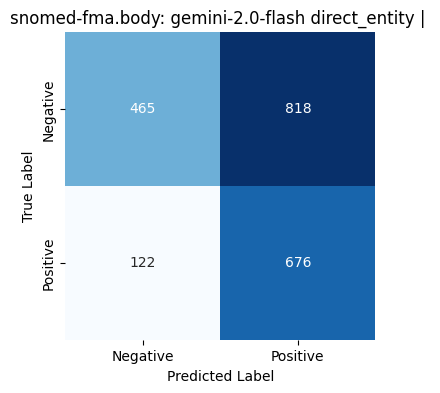

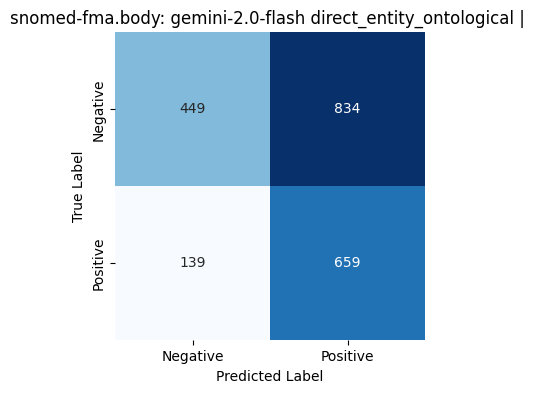

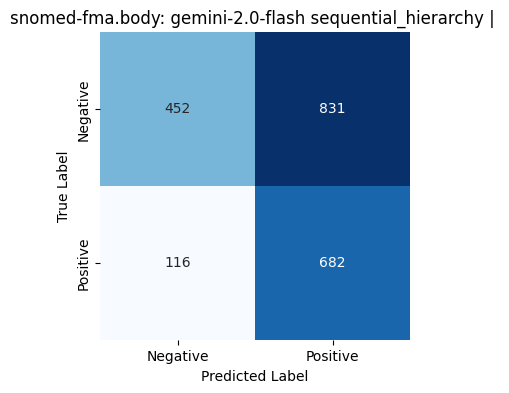

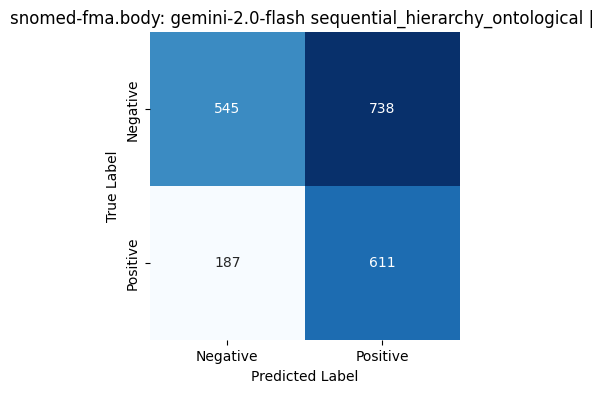

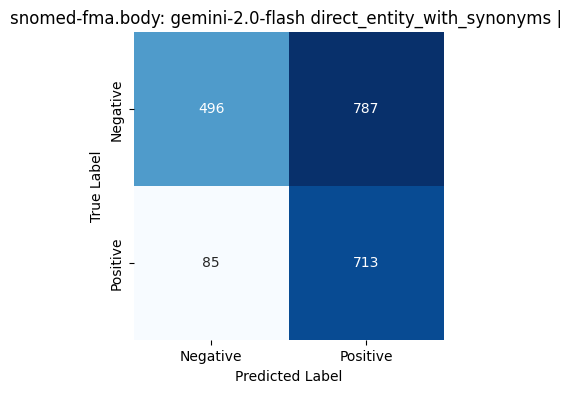

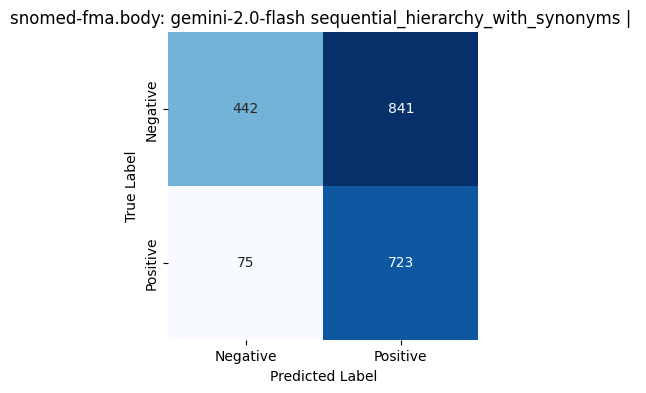

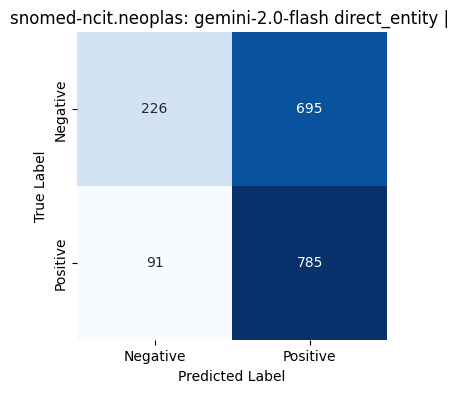

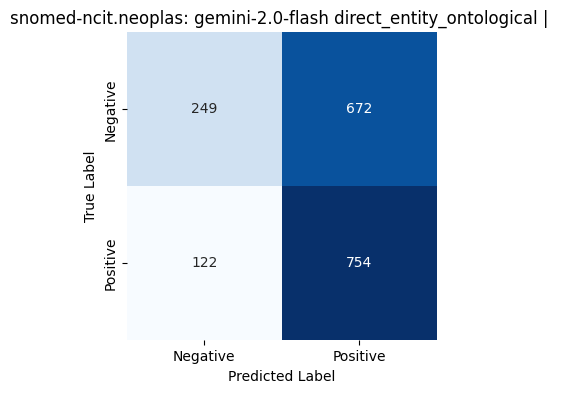

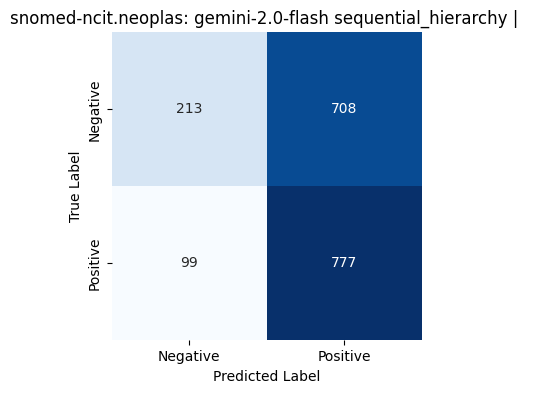

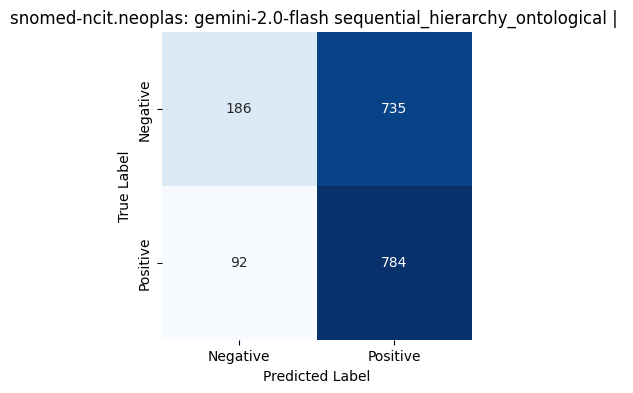

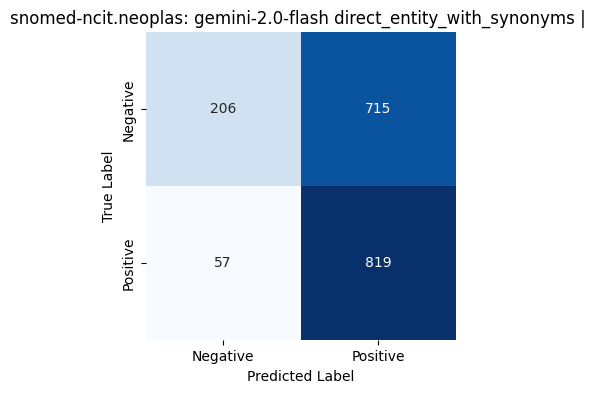

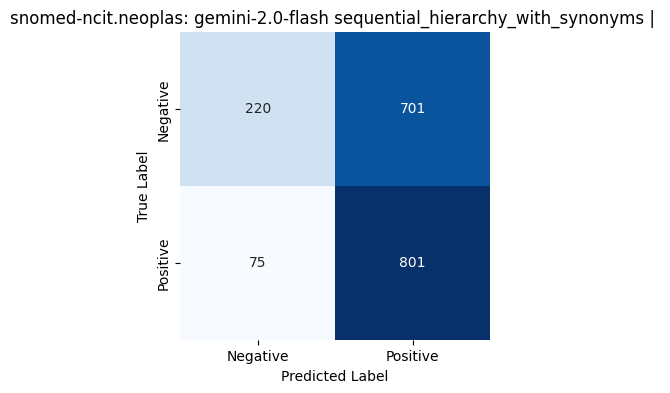

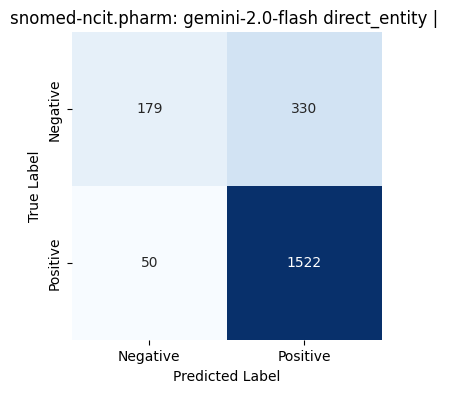

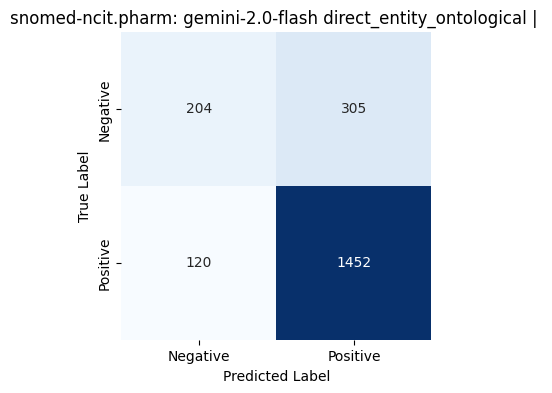

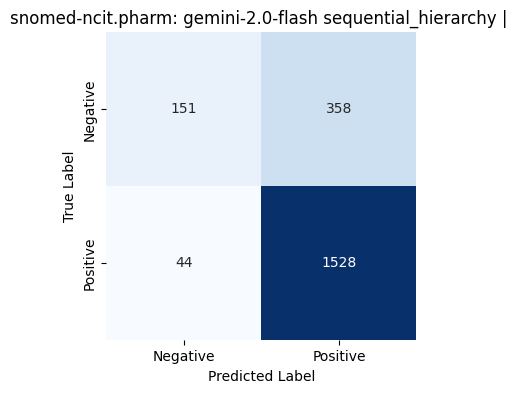

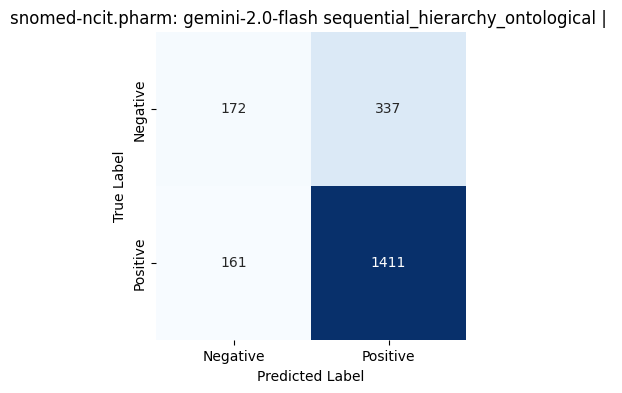

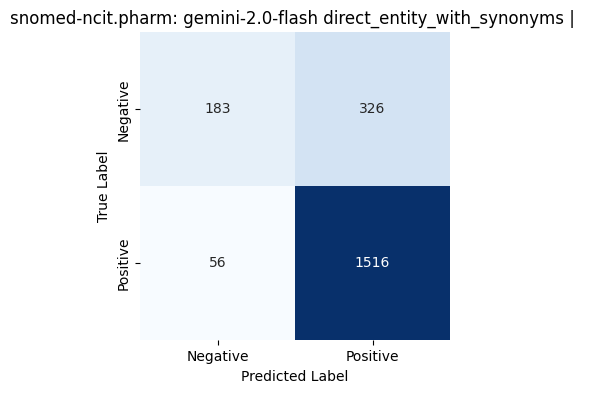

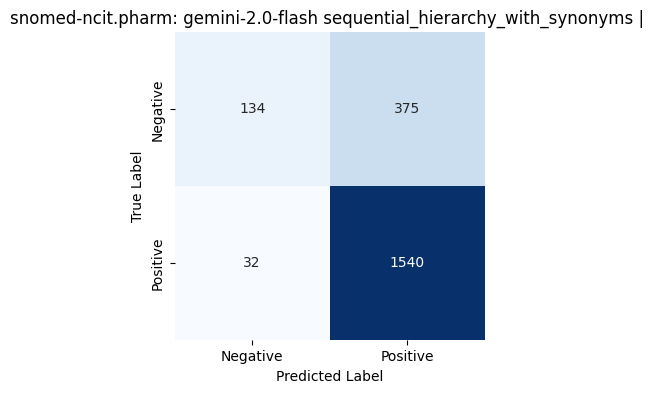

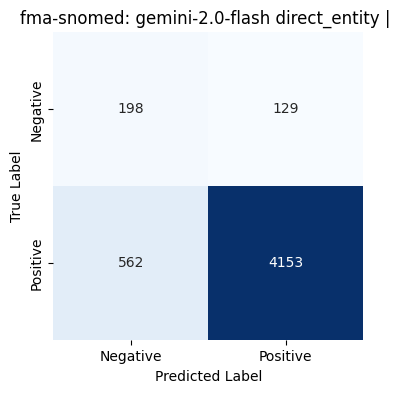

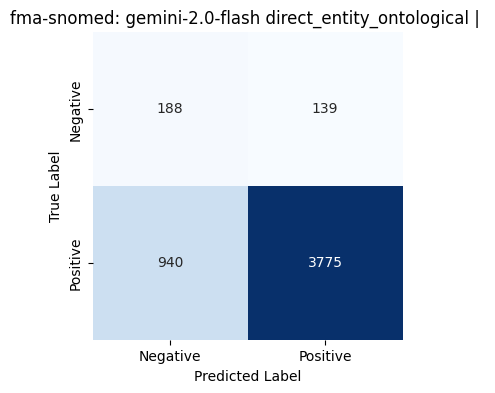

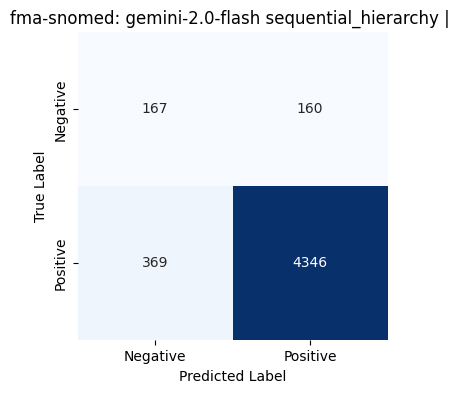

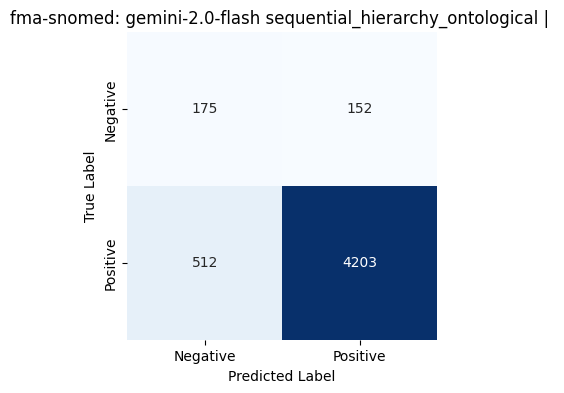

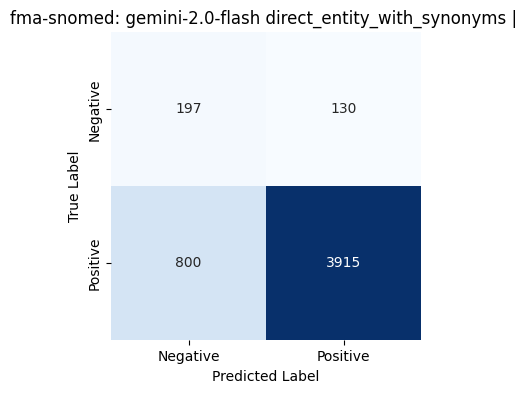

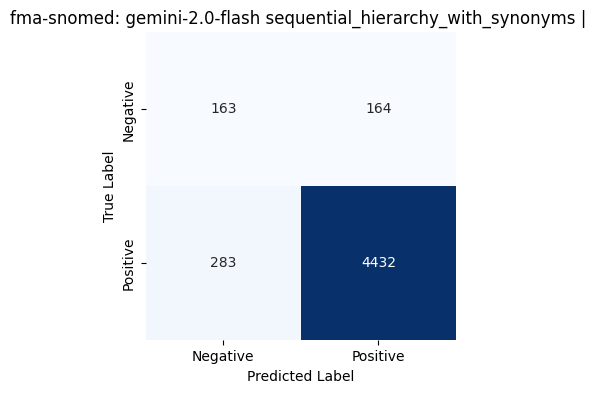

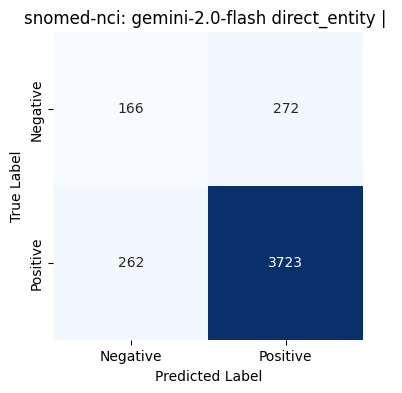

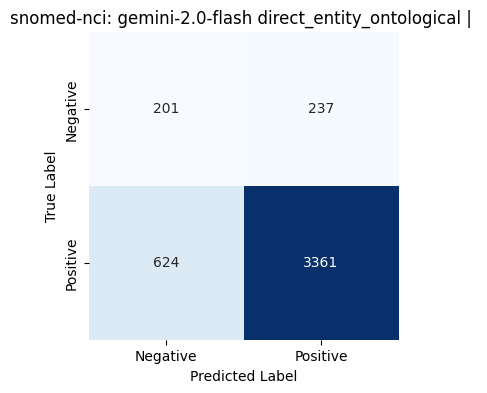

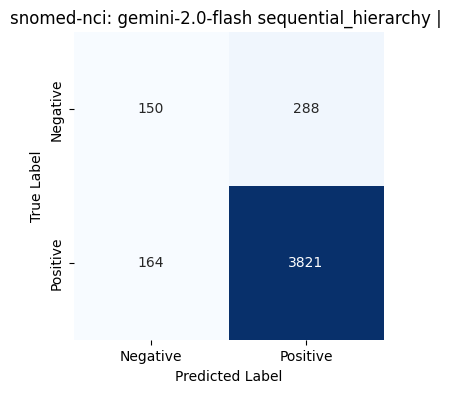

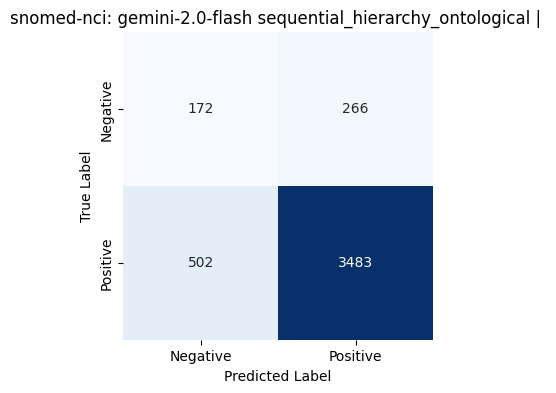

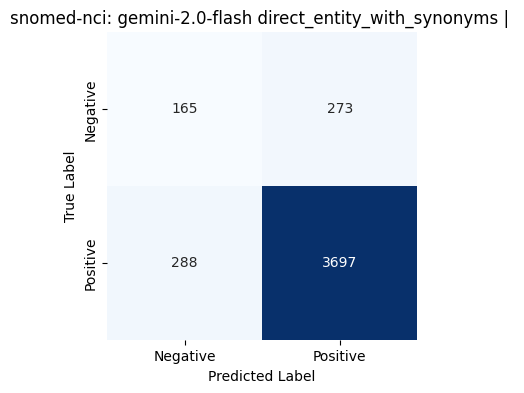

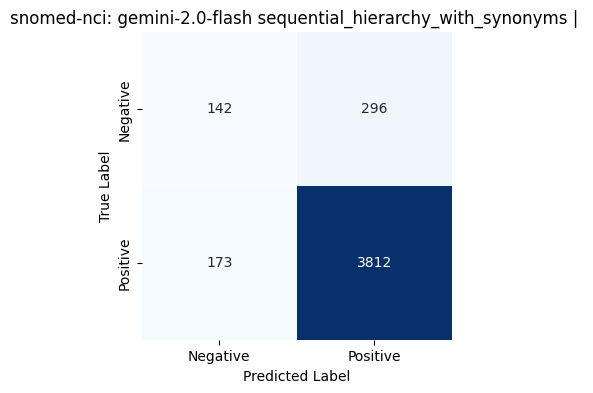

In [ ]:
for DATASET_NAME in DATASETS_MAP:
    for SET_NAME in DATASETS_MAP[DATASET_NAME]:
        for MODEL in MODELS:
            llm_oracle = (
                OpenAIServer(
                    api_key=os.environ["GEMINI_API_KEY"],
                    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
                )
                if MODEL.startswith("gemini")
                else OpenAIServer(api_key=os.environ["OPENAI_API_KEY"])
            )
            llm_oracle.add_system_context(BASELINE_INITIALIZATION_MESSAGE)

            run_path = format_run_path()
            print(f"Run path: {run_path}, dataset: {DATASET_NAME}, set: {SET_NAME}, model: {MODEL}")

            for current_exp_name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
                oracle_candidate_pairs = load_precomputed_oracle_pairs(DATASET_NAME, SET_NAME, prompt_function)

                results, tokens_usage, confidences = parallel_samples_process(
                    oracle_candidate_pairs, llm_oracle, onto_src, onto_tgt, MODEL, MAX_WORKERS, prompt_function
                )
                prediction_path, stats_path, diagram_path = format_storing_pathes_from_run_path(
                    run_path, SET_NAME, MODEL, current_exp_name, suffix=""
                )
                save_run_results(results, prediction_path, columns=["Source", "Target", "Prediction", "Confidence"])
                plot_usage_histograms(
                    tokens_usage, confidences, do_plot=False, do_print=True, suptitle=current_exp_name
                )
                try:
                    predictions = get_predictions_with_gt(
                        run_path, DATASET_NAME, SET_NAME, MODEL, current_exp_name, suffix=""
                    )
                    analyze_results(
                        predictions,
                        print_results=True,
                        plot_confusion_matrix=False,
                        subtitle=f"{SET_NAME}: {MODEL} {current_exp_name} | ",
                        cm_save_path=diagram_path,
                        stats_path=stats_path,
                    )
                except Exception as e:  # noqa: BLE001
                    print(f"Error: {e}")

                print("\n")

            store_run_metrics_df(EXP_NAMES_TO_PROMPT_FUNCTIONS, run_path, DATASET_NAME, SET_NAME, MODEL)

## Analysis


In [30]:
runs_array = []

for directory in sorted(RUN_DIR.iterdir(), key=lambda x: x.name, reverse=True):
    if not directory.is_dir():
        continue
    for file in directory.iterdir():
        if '_' not in file.name:
            continue
        subset_name, model_name = file.name.split('_')[:2]
        dataset_name = SUBSET_TO_DATASET_MAP.get(subset_name)
    runs_array.append((directory.name, model_name, subset_name, dataset_name))

len(runs_array), runs_array

(27,
 [('2025-05-01_11-47-16', 'gemini-2.0-flash', 'snomed-nci', 'largebio'),
  ('2025-05-01_11-37-30', 'gemini-2.0-flash-lite', 'snomed-nci', 'largebio'),
  ('2025-05-01_11-24-31', 'gemini-2.0-flash', 'fma-snomed', 'largebio'),
  ('2025-05-01_11-19-48', 'gemini-2.0-flash-lite', 'fma-snomed', 'largebio'),
  ('2025-05-01_11-15-05',
   'gemini-2.0-flash',
   'snomed-ncit.pharm',
   'bioml-2024'),
  ('2025-05-01_11-12-35',
   'gemini-2.0-flash-lite',
   'snomed-ncit.pharm',
   'bioml-2024'),
  ('2025-05-01_11-07-00',
   'gemini-2.0-flash',
   'snomed-ncit.neoplas',
   'bioml-2024'),
  ('2025-05-01_11-06-39',
   'gemini-2.0-flash-lite',
   'snomed-ncit.neoplas',
   'bioml-2024'),
  ('2025-05-01_10-56-46', 'gemini-2.0-flash', 'snomed-fma.body', 'bioml-2024'),
  ('2025-05-01_10-50-33',
   'gemini-2.0-flash-lite',
   'snomed-fma.body',
   'bioml-2024'),
  ('2025-05-01_10-13-02', 'gemini-2.0-flash-lite', 'fma-snomed', 'largebio'),
  ('2025-04-10_22-11-36', 'gemini-2.0-flash', 'ncit-doid', 'bio

In [34]:
runs = [
    ('2025-05-01_11-47-16', 'gemini-2.0-flash', 'snomed-nci', 'largebio'),
    ('2025-05-01_11-37-30', 'gemini-2.0-flash-lite', 'snomed-nci', 'largebio'),
    ('2025-05-01_11-24-31', 'gemini-2.0-flash', 'fma-snomed', 'largebio'),
    ('2025-05-01_11-19-48', 'gemini-2.0-flash-lite', 'fma-snomed', 'largebio'),
    ('2025-05-01_11-15-05', 'gemini-2.0-flash', 'snomed-ncit.pharm', 'bioml-2024'),
    ('2025-05-01_11-12-35', 'gemini-2.0-flash-lite', 'snomed-ncit.pharm', 'bioml-2024'),
    ('2025-05-01_11-07-00', 'gemini-2.0-flash', 'snomed-ncit.neoplas', 'bioml-2024'),
    ('2025-05-01_11-06-39', 'gemini-2.0-flash-lite', 'snomed-ncit.neoplas', 'bioml-2024'),
    ('2025-05-01_10-56-46', 'gemini-2.0-flash', 'snomed-fma.body', 'bioml-2024'),
    ('2025-05-01_10-50-33', 'gemini-2.0-flash-lite', 'snomed-fma.body', 'bioml-2024'),
    ('2025-05-01_10-13-02', 'gemini-2.0-flash-lite', 'fma-snomed', 'largebio'),
    ('2025-04-10_22-11-36', 'gemini-2.0-flash', 'ncit-doid', 'bioml-2024'),
    ('2025-04-10_00-33-19', 'gemini-2.0-flash-lite', 'ncit-doid', 'bioml-2024'),
    ('2025-04-06_22-05-02', 'gemini-2.0-flash-lite', 'omim-ordo', 'bioml-2024'),
    ('2025-04-06_19-27-41', 'gemini-2.0-flash', 'omim-ordo', 'bioml-2024'),
    ('2025-04-06_14-51-00', 'gemini-2.0-flash-lite', 'fma-nci', 'largebio'),
    ('2025-04-06_14-18-46', 'gemini-2.0-flash', 'fma-nci', 'largebio'),
    ('2025-04-04_19-41-28', 'gemini-2.0-flash', 'human-mouse', 'anatomy'),
    ('2025-04-04_19-23-47', 'gemini-2.0-flash-lite', 'human-mouse', 'anatomy'),
    ('2025-04-04_00-43-16', 'gemini-2.0-flash', 'fma-snomed', 'largebio'),
    ('2025-03-28_10-15-04', 'gpt-4o-mini', 'fma-nci', 'largebio'),
    ('2025-03-19_23-32-20', 'gpt-4o-mini', 'omim-ordo', 'bioml-2024'),
    ('2025-03-19_22-17-52', 'gpt-4o-mini', 'ncit-doid', 'bioml-2024'),
    ('2025-03-19_19-48-41', 'gpt-4o-mini', 'human-mouse', 'anatomy'),
    ('2025-03-14_00-40-55', 'gpt-4o-mini', 'ncit-doid', 'bioml-2024'),
    ('2025-03-12_17-21-53', 'gpt-4o-mini', 'human-mouse', 'anatomy'),
    ('2025-03-12_14-43-32', 'gpt-4o-mini', 'omim-ordo', 'bioml-2024')
 ]

suffix = ""

dfs = []
for run_subdir, model, set_name, dataset in runs:
    metrics_df = read_run_metrics_df(run_subdir, suffix)
    for col, value in zip(["Dataset", "SubSet", "Model"], [dataset, set_name, model]):
        if col not in metrics_df.columns:
            metrics_df[col] = value
    metrics_df["Run"] = run_subdir
    dfs.append(metrics_df)

results_df = pd.concat(dfs, ignore_index=True)
results_df = results_df.sort_values(by=["Dataset", "SubSet", "Model", "Experiment"])

results_df.to_csv(RUN_DIR / f"all_runs_metrics{suffix}.csv", index=False)
results_df

,Experiment,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Dataset,SubSet,Model,Run
102,direct_entity,0.8392,0.8476,0.9521,0.8968,0.5283,0.9521,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
103,direct_entity_ontological,0.8266,0.8495,0.9281,0.8871,0.5472,0.9281,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
106,direct_entity_with_synonyms,0.8492,0.8392,0.9829,0.9054,0.4811,0.9829,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
104,sequential_hierarchy,0.8442,0.8423,0.9692,0.9013,0.5000,0.9692,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
105,sequential_hierarchy_ontological,0.7990,0.8354,0.9041,0.8684,0.5094,0.9041,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
107,sequential_hierarchy_with_synonyms,0.8518,0.8416,0.9829,0.9068,0.4906,0.9829,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
108,direct_entity,0.8090,0.9000,0.8322,0.8648,0.7453,0.8322,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47
109,direct_entity_ontological,0.7186,0.8947,0.6986,0.7846,0.7736,0.6986,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47
112,direct_entity_with_synonyms,0.8141,0.8283,0.9418,0.8814,0.4623,0.9418,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47
110,sequential_hierarchy,0.8266,0.8495,0.9281,0.8871,0.5472,0.9281,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47


### Rerun evaluation

In [ ]:
runs = [
    ('2025-05-01_11-47-16', 'gemini-2.0-flash', 'snomed-nci', 'largebio'),
    ('2025-05-01_11-37-30', 'gemini-2.0-flash-lite', 'snomed-nci', 'largebio'),
    ('2025-05-01_11-24-31', 'gemini-2.0-flash', 'fma-snomed', 'largebio'),
    ('2025-05-01_11-19-48', 'gemini-2.0-flash-lite', 'fma-snomed', 'largebio'),
    ('2025-05-01_11-15-05', 'gemini-2.0-flash', 'snomed-ncit.pharm', 'bioml-2024'),
    ('2025-05-01_11-12-35', 'gemini-2.0-flash-lite', 'snomed-ncit.pharm', 'bioml-2024'),
    ('2025-05-01_11-07-00', 'gemini-2.0-flash', 'snomed-ncit.neoplas', 'bioml-2024'),
    ('2025-05-01_11-06-39', 'gemini-2.0-flash-lite', 'snomed-ncit.neoplas', 'bioml-2024'),
    ('2025-05-01_10-56-46', 'gemini-2.0-flash', 'snomed-fma.body', 'bioml-2024'),
    ('2025-05-01_10-50-33', 'gemini-2.0-flash-lite', 'snomed-fma.body', 'bioml-2024'),
    ('2025-05-01_10-13-02', 'gemini-2.0-flash-lite', 'fma-snomed', 'largebio'),
    ('2025-04-10_22-11-36', 'gemini-2.0-flash', 'ncit-doid', 'bioml-2024'),
    ('2025-04-10_00-33-19', 'gemini-2.0-flash-lite', 'ncit-doid', 'bioml-2024'),
    ('2025-04-06_22-05-02', 'gemini-2.0-flash-lite', 'omim-ordo', 'bioml-2024'),
    ('2025-04-06_19-27-41', 'gemini-2.0-flash', 'omim-ordo', 'bioml-2024'),
    ('2025-04-06_14-51-00', 'gemini-2.0-flash-lite', 'fma-nci', 'largebio'),
    ('2025-04-06_14-18-46', 'gemini-2.0-flash', 'fma-nci', 'largebio'),
    ('2025-04-04_19-41-28', 'gemini-2.0-flash', 'human-mouse', 'anatomy'),
    ('2025-04-04_19-23-47', 'gemini-2.0-flash-lite', 'human-mouse', 'anatomy'),
    ('2025-04-04_00-43-16', 'gemini-2.0-flash', 'fma-snomed', 'largebio'),
    ('2025-03-28_10-15-04', 'gpt-4o-mini', 'fma-nci', 'largebio'),
    ('2025-03-19_23-32-20', 'gpt-4o-mini', 'omim-ordo', 'bioml-2024'),
    ('2025-03-19_22-17-52', 'gpt-4o-mini', 'ncit-doid', 'bioml-2024'),
    ('2025-03-19_19-48-41', 'gpt-4o-mini', 'human-mouse', 'anatomy'),
    ('2025-03-14_00-40-55', 'gpt-4o-mini', 'ncit-doid', 'bioml-2024'),
    ('2025-03-12_17-21-53', 'gpt-4o-mini', 'human-mouse', 'anatomy'),
    ('2025-03-12_14-43-32', 'gpt-4o-mini', 'omim-ordo', 'bioml-2024')
 ]

27

In [ ]:
suffix= ""
for run_path, MODEL, SET_NAME, DATASET_NAME in tqdm(runs[:]):
    run_path = RUN_DIR / run_path
    print(f"Run path: {run_path}, dataset: {DATASET_NAME}, set: {SET_NAME}, model: {MODEL}")
    for current_exp_name in tqdm(EXP_NAMES_TO_PROMPT_FUNCTIONS, disable=True):
        try:
            prediction_path, stats_path, diagram_path = format_storing_pathes_from_run_path(
                run_path, SET_NAME, MODEL, current_exp_name, suffix
            )
            predictions = get_predictions_with_gt(run_path, DATASET_NAME, SET_NAME, MODEL, current_exp_name, suffix)
            analyze_results(
                predictions,
                print_results=False,
                plot_confusion_matrix=False,
                subtitle=f"{SET_NAME}: {MODEL} {current_exp_name} | ",
                cm_save_path=diagram_path,
                stats_path=stats_path,
            )
        except Exception as e:  # noqa: BLE001
            print(f"Error: {e}")
            # raise e

    store_run_metrics_df(EXP_NAMES_TO_PROMPT_FUNCTIONS, run_path, DATASET_NAME, SET_NAME, MODEL, suffix)

  0%|          | 0/27 [00:00<?, ?it/s]

Run path: runs/2025-05-01_11-47-16, dataset: largebio, set: snomed-nci, model: gemini-2.0-flash


  4%|▎         | 1/27 [00:07<03:14,  7.48s/it]

Run path: runs/2025-05-01_11-37-30, dataset: largebio, set: snomed-nci, model: gemini-2.0-flash-lite


  7%|▋         | 2/27 [00:12<02:26,  5.84s/it]

...

Error: [Errno 2] No such file or directory: 'runs/2025-03-14_00-40-55/ncit-doid_gpt-4o-mini_direct_entity_with_synonyms_results_reduced.csv'
Error: [Errno 2] No such file or directory: 'runs/2025-03-14_00-40-55/ncit-doid_gpt-4o-mini_sequential_hierarchy_with_synonyms_results_reduced.csv'
File not found for direct_entity_with_synonyms in runs/2025-03-14_00-40-55
File not found for sequential_hierarchy_with_synonyms in runs/2025-03-14_00-40-55
Run path: runs/2025-03-12_17-21-53, dataset: anatomy, set: human-mouse, model: gpt-4o-mini


 96%|█████████▋| 26/27 [00:44<00:00,  1.43it/s]

Error: [Errno 2] No such file or directory: 'runs/2025-03-12_17-21-53/human-mouse_gpt-4o-mini_direct_entity_with_synonyms_results_reduced.csv'
Error: [Errno 2] No such file or directory: 'runs/2025-03-12_17-21-53/human-mouse_gpt-4o-mini_sequential_hierarchy_with_synonyms_results_reduced.csv'
File not found for direct_entity_with_synonyms in runs/2025-03-12_17-21-53
File not found for sequential_hierarchy_with_synonyms in runs/2025-03-12_17-21-53
Run path: runs/2025-03-12_14-43-32, dataset: bioml-2024, set: omim-ordo, model: gpt-4o-mini


100%|██████████| 27/27 [00:45<00:00,  1.69s/it]

Error: [Errno 2] No such file or directory: 'runs/2025-03-12_14-43-32/omim-ordo_gpt-4o-mini_direct_entity_with_synonyms_results_reduced.csv'
Error: [Errno 2] No such file or directory: 'runs/2025-03-12_14-43-32/omim-ordo_gpt-4o-mini_sequential_hierarchy_with_synonyms_results_reduced.csv'
File not found for direct_entity_with_synonyms in runs/2025-03-12_14-43-32
File not found for sequential_hierarchy_with_synonyms in runs/2025-03-12_14-43-32
